# Pre-Release Sales Prediction for Steam Games
## Notebook 1 of 3 — Preprocessing and Transformation

**Research question.** How accurately can the commercial performance of a PC game be predicted
using only information that is available before or on its release day?

**Relation to the parent paper.** Gray, Shalan and Kadlec (*Sales Predictions for Video Games
Using Predictive Analytics of Market Data*, IEEE CICN 2024) predicted global sales with Linear
Regression and a Decision Tree and reported R² = 1.000. Their predictors included the four
regional sales columns, which sum exactly to the target, and review counts that accumulate after
release. The reported accuracy therefore reflects information leakage rather than predictive
skill, and the model cannot be applied to a game that has not yet been released. This study
retains the parent paper's modeling methods (Linear Regression, Decision Tree), adds Random
Forest and 5-fold cross-validation, and restricts every predictor to information that exists
before or at launch.

**Analysis pipeline**

| Stage | Notebook | Content |
|---|---|---|
| 1. Preprocessing | 01 | Data introduction, data wrangling, label validation, leakage audit |
| 2. Transformation | 01 | Target construction, pre-release and release-day indicators |
| 3. Analysis | 02 | Descriptive statistics, target distribution, temporal structure, indicator relationships |
| 4. Modeling | 03 | Data split, baseline, Linear Regression, Decision Tree, Random Forest |
| 5. Validation | 03 | 5-fold grouped cross-validation, chronological hold-out test |
| 6. Decision making | 03 | Model selection, key drivers, practical use, limitations |

In [1]:
import json
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import kagglehub

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})

FIG_DIR = os.path.join("..", "outputs", "figures")
TAB_DIR = os.path.join("..", "outputs", "tables")
DATA_DIR = os.path.join("..", "data", "processed")
for d in (FIG_DIR, TAB_DIR, DATA_DIR):
    os.makedirs(d, exist_ok=True)

RELEASE_START = pd.Timestamp("2010-01-01")   # first release year with a cohort of >= 200 labeled games
RELEASE_CUTOFF = pd.Timestamp("2024-06-30")  # last release date with >= 12 months of owner data (Section 2.4)
HIT_OWNERS = 100_000                         # definition of a commercial "hit"

C:\Users\Nobutaka\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---
# 1. Data Introduction

**Source.** [Steam Games Dataset](https://www.kaggle.com/datasets/fronkongames/steam-games-dataset)
(Kaggle, fronkongames, version 49). The dataset combines two public sources:

- **Steam store pages** — the information a customer sees when browsing a game: price, release
  date, developer and publisher, genres, feature categories, supported languages, platforms,
  screenshots and description text.
- **SteamSpy** — third-party estimates of each game's number of owners, reported as ranges
  (for example, 20,000 – 50,000), together with engagement statistics such as review counts,
  playtime and peak concurrent players.

**Unit of analysis.** One row per Steam application (AppID).

**Target.** SteamSpy's estimated number of owners is used as the measure of sales. Steam does not
publish unit sales, and owner estimates are the standard public proxy for them.

**Why this dataset.** Unlike the VGChartz data used by the parent paper, which contains little
beyond genre, platform, publisher and year, the Steam store page records the product decisions a
publisher makes before launch (pricing, localisation, platform support, store presentation).
These are the inputs a pre-release forecast can legitimately use.

In [2]:
path = kagglehub.dataset_download("fronkongames/steam-games-dataset")
with open(os.path.join(path, "games.json"), encoding="utf-8") as f:
    raw_json = json.load(f)


def first_package_text(v):
    for p in v.get("packages") or []:
        for s in p.get("subs") or []:
            if s.get("text"):
                return s["text"]
    return None


records = []
for appid, v in raw_json.items():
    records.append({
        "appid": int(appid),
        "name": v.get("name"),
        "release_date": v.get("release_date"),
        "estimated_owners": v.get("estimated_owners"),
        "price_current": v.get("price"),
        "package_text": first_package_text(v),
        "required_age": v.get("required_age"),
        "short_description": v.get("short_description") or "",
        "detailed_description_len": len(v.get("detailed_description") or ""),
        "website": v.get("website") or "",
        "support_email": v.get("support_email") or "",
        "windows": v.get("windows"), "mac": v.get("mac"), "linux": v.get("linux"),
        "supported_languages": v.get("supported_languages") or [],
        "full_audio_languages": v.get("full_audio_languages") or [],
        "developers": v.get("developers") or [],
        "publishers": v.get("publishers") or [],
        "categories": v.get("categories") or [],
        "genres": v.get("genres") or [],
        "n_screenshots": len(v.get("screenshots") or []),
        "n_movies": len(v.get("movies") or []),
        "metacritic_score": v.get("metacritic_score"),
        "positive": v.get("positive"), "negative": v.get("negative"),
        "recommendations": v.get("recommendations"),
        "peak_ccu": v.get("peak_ccu"),
        "average_playtime_forever": v.get("average_playtime_forever"),
        "achievements": v.get("achievements"),
        "dlc_count": v.get("dlc_count"),
        "tags": v.get("tags") or {},
    })
del raw_json

df = pd.DataFrame(records)
print(f"Applications: {len(df):,} | fields retained: {df.shape[1]}")
df[["appid", "name", "release_date", "price_current", "estimated_owners", "genres"]].head(3)

Applications: 141,900 | fields retained: 31


,appid,name,release_date,price_current,estimated_owners,genres
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0.00,0 - 0,[]
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",5.24,0 - 20000,[Adventure]
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",4.99,0 - 20000,[Casual]


---
# 2. Preprocessing (Data Wrangling)

## 2.1 Source file selection

The dataset is distributed as `games.csv` and `games.json`. The CSV header contains a defect: the
field names `Discount` and `DLC count` are merged into a single name (`DiscountDLC count`), so the
header has one fewer name than each data row. A standard CSV reader therefore assigns every value
to the column on its left (for example, the game title is read as `AppID`). The JSON file does not
have this defect, contains more applications, and retains fields absent from the CSV
(`short_description`, `packages`). **All processing uses `games.json`.**

In [3]:
csv_path = os.path.join(path, "games.csv")
csv_header = pd.read_csv(csv_path, nrows=0).columns.tolist()
csv_rows = len(pd.read_csv(csv_path, usecols=[0], index_col=False, low_memory=False))
print(f"games.csv : {len(csv_header)} header names, merged name present: {'DiscountDLC count' in csv_header}, {csv_rows:,} rows")
print(f"games.json: {len(df):,} applications")
print(f"Applications with trailer data (`movies`): {(df['n_movies'] > 0).sum()}  -> trailer information is unavailable in this version")

games.csv : 39 header names, merged name present: True, 125,855 rows
games.json: 141,900 applications
Applications with trailer data (`movies`): 0  -> trailer information is unavailable in this version


## 2.2 Parsing dates and owner ranges

Release dates are stored as text (e.g. `"Jul 29, 2016"`) and owner estimates as a range string
(e.g. `"20000 - 50000"`). Both are converted to typed columns.

In [4]:
df["release_dt"] = pd.to_datetime(df["release_date"], errors="coerce", format="mixed")
bounds = df["estimated_owners"].str.extract(r"(\d+)\s*-\s*(\d+)").astype(float)
df["owners_low"], df["owners_high"] = bounds[0], bounds[1]

print(f"Unparseable release dates: {df['release_dt'].isna().sum()}")
order = df.drop_duplicates("estimated_owners").sort_values("owners_low")["estimated_owners"]
df["estimated_owners"].value_counts().reindex(order).rename("applications").to_frame().T

Unparseable release dates: 0


estimated_owners,0 - 0,0 - 20000,20000 - 50000,50000 - 100000,100000 - 200000,200000 - 500000,500000 - 1000000,1000000 - 2000000,2000000 - 5000000,5000000 - 10000000,10000000 - 20000000,20000000 - 50000000,50000000 - 100000000,100000000 - 200000000
applications,38990,77328,11400,5359,3457,2857,1155,729,405,125,51,31,9,4


## 2.3 Validity of the owner labels

**Issue.** About 27% of applications report `"0 - 0"` owners. Read literally, these rows would form
the lowest sales class. However, a value of zero can also mean that SteamSpy never collected data
for the application.

**Test.** If `"0 - 0"` were a genuine measurement of very low sales, these games would still show
some player activity. The table compares them with the lowest genuine range (`"0 - 20000"`).

In [5]:
zero = df["estimated_owners"] == "0 - 0"
low = df["estimated_owners"] == "0 - 20000"
reviews = df["positive"] + df["negative"]
evidence = pd.DataFrame({
    '"0 - 0"': [(reviews[zero] > 0).mean(), (df.loc[zero, "peak_ccu"] > 0).mean(),
                (df.loc[zero, "average_playtime_forever"] > 0).mean(), (df.loc[zero, "tags"].str.len() > 0).mean()],
    '"0 - 20000"': [(reviews[low] > 0).mean(), (df.loc[low, "peak_ccu"] > 0).mean(),
                    (df.loc[low, "average_playtime_forever"] > 0).mean(), (df.loc[low, "tags"].str.len() > 0).mean()],
}, index=["share with any review", "share with peak players > 0", "share with playtime > 0", "share with user tags"])
evidence.style.format("{:.1%}")

,"""0 - 0""","""0 - 20000"""
share with any review,0.0%,74.3%
share with peak players > 0,0.0%,10.1%
share with playtime > 0,0.0%,12.6%
share with user tags,0.0%,74.8%


**Finding.** Every SteamSpy-derived field is empty for all `"0 - 0"` applications, whereas most games
in the lowest genuine range have reviews and user tags. `"0 - 0"` therefore indicates a **missing
label**, not zero sales. **Resolution:** these rows are excluded rather than assigned to the lowest
class.

## 2.4 Label coverage over time and right-censoring

**Issue.** Two time-related problems affect the target:
1. **Label staleness.** If SteamSpy stopped updating, recent games would be systematically unlabeled.
2. **Right-censoring.** Owners accumulate over a game's life. A game released shortly before the data
   snapshot has had little time to sell and would appear less successful than it will become.

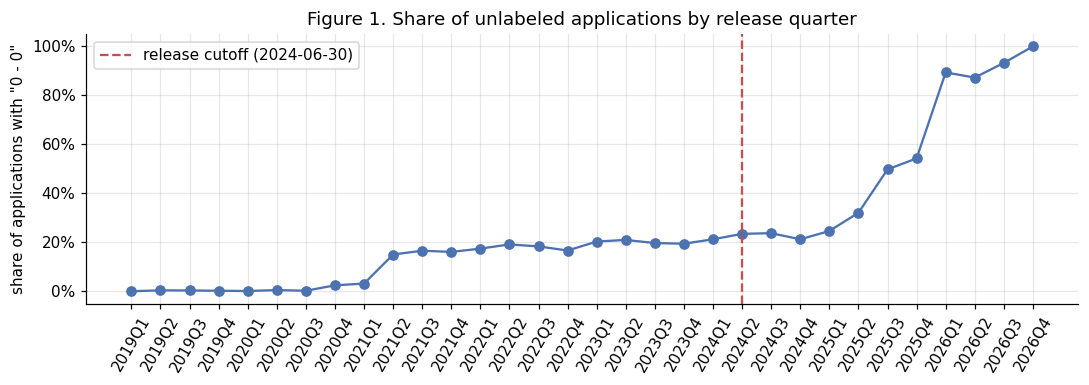

In [6]:
recent = df[df["release_dt"] >= "2019-01-01"]
by_q = recent.groupby(recent["release_dt"].dt.to_period("Q")).agg(
    applications=("appid", "size"), share_unlabeled=("estimated_owners", lambda s: (s == "0 - 0").mean()))

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(by_q.index.astype(str), by_q["share_unlabeled"], marker="o", color="#4C72B0")
ax.axvline(str(RELEASE_CUTOFF.to_period("Q")), color="#C44E52", ls="--", label=f"release cutoff ({RELEASE_CUTOFF.date()})")
ax.set_ylabel('share of applications with "0 - 0"')
ax.set_title("Figure 1. Share of unlabeled applications by release quarter")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.tick_params(axis="x", rotation=60)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig01_unlabeled_share_by_quarter.png"), dpi=150)
plt.show()

**Finding.** The unlabeled share is stable at roughly 20–25% from 2021 to early 2025, then rises
sharply from mid-2025 (about 50%) to about 90% in 2026. Owner estimates therefore stopped updating
around mid-2025.

**Resolution.** The analysis is restricted to games released **on or before 30 June 2024**, which
gives every retained game at least twelve months of owner data before labels stop updating. The
start of the window is set to **1 January 2010**, the first year with at least 200 labeled games;
earlier years contain too few games to define a reliable per-year baseline (Section 3.1). The
remaining difference in time on sale between, for example, a 2012 and a 2023 release is handled by
the target definition in Section 3.1.

## 2.5 Scope: standalone games only

**Issue.** Steam lists several kinds of application that are not commercial game products:
- **Playtests and demos** — free test builds published as separate AppIDs.
- **Software** — utilities, video editing, design and development tools.

**Resolution.** Playtests and demos are identified by name. Software is identified by genre: an
application is removed when it carries a software genre and none of the core game genres.

In [7]:
name_l = df["name"].fillna("").str.lower()
is_test_build = name_l.str.contains(r"\bplaytest\b|\bdemo\b")

SOFTWARE_GENRES = {"Utilities", "Design & Illustration", "Animation & Modeling", "Video Production",
                   "Game Development", "Photo Editing", "Audio Production", "Software Training",
                   "Web Publishing", "Accounting"}
GAME_GENRES = {"Action", "Adventure", "Casual", "RPG", "Simulation", "Strategy", "Sports", "Racing",
               "Massively Multiplayer"}
is_software = df["genres"].apply(lambda L: bool(SOFTWARE_GENRES & set(L)) and not (GAME_GENRES & set(L)))
is_labeled = df["estimated_owners"] != "0 - 0"
in_window = df["release_dt"].between(RELEASE_START, RELEASE_CUTOFF)

steps = [
    ("All applications in games.json", pd.Series(True, index=df.index)),
    ("Remove playtests and demos", ~is_test_build),
    ("Remove non-game software", ~is_software),
    ('Remove missing labels ("0 - 0")', is_labeled),
    (f"Keep releases {RELEASE_START.date()} to {RELEASE_CUTOFF.date()}", in_window),
]
mask = pd.Series(True, index=df.index)
funnel = []
for label, cond in steps:
    mask &= cond
    funnel.append({"step": label, "rows remaining": int(mask.sum())})
funnel = pd.DataFrame(funnel)
funnel["rows removed"] = (-funnel["rows remaining"].diff()).fillna(0).astype(int)

games = df[mask].copy().reset_index(drop=True)
# Pool of all standalone games, labeled or not; used later for counts that do not require labels
pool = df[~is_test_build & ~is_software & df["release_dt"].notna()].copy()
funnel

,step,rows remaining,rows removed
0,All applications in games.json,141900,0
1,Remove playtests and demos,133688,8212
2,Remove non-game software,132243,1445
3,"Remove missing labels (""0 - 0"")",101630,30613
4,Keep releases 2010-01-01 to 2024-06-30,76074,25556


## 2.6 Duplicate titles

**Issue.** Some games appear under more than one AppID (re-releases, remasters listed under the same
name, regional or edition variants). If two copies of the same title were split between the
training and test data, the model would be evaluated partly on a game it had already seen.

**Resolution.** Titles are not deleted, because each AppID has its own owner count. Instead, a
normalised title key is created and used in Notebook 3 to keep all copies of a title in the same
cross-validation fold.

In [8]:
games["title_key"] = games["name"].fillna("").str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
# Titles with no Latin letters or digits (e.g. fully non-Latin names) reduce to an empty key; use the AppID instead
empty_key = games["title_key"] == ""
games.loc[empty_key, "title_key"] = "appid_" + games.loc[empty_key, "appid"].astype(str)
dup_sizes = games.groupby("title_key").size()
print(f"Distinct title keys: {len(dup_sizes):,}")
print(f"Title keys shared by more than one AppID: {(dup_sizes > 1).sum():,} "
      f"({games['title_key'].map(dup_sizes).gt(1).sum():,} rows)")

Distinct title keys: 74,993
Title keys shared by more than one AppID: 843 (1,924 rows)


## 2.7 Leakage audit and variable selection

**Principle.** A variable may be used only if its value would be known on or before the release
date. Variables that are measured on players, accumulate after launch, or are commonly changed
after launch in response to commercial performance are excluded. This rule removes the class of
predictors responsible for the parent paper's R² = 1.000.

A quick check confirms that the Steam equivalents of the parent paper's post-release predictors
would leak in the same way: review counts are strongly correlated with the target.

In [9]:
chk = games.assign(reviews=games["positive"] + games["negative"],
                   owners_mid=(games["owners_low"] + games["owners_high"]) / 2)
leak_check = pd.DataFrame({
    "Spearman correlation with owners": [
        chk[c].corr(chk["owners_mid"], method="spearman")
        for c in ["reviews", "recommendations", "peak_ccu", "average_playtime_forever"]]
}, index=["review count", "recommendations", "peak concurrent players", "average playtime"])
leak_check.round(3)

,Spearman correlation with owners
review count,0.593
recommendations,0.574
peak concurrent players,0.492
average playtime,0.583


In [10]:
audit = pd.DataFrame([
    ("Price (list price at launch)", "Pre-release", "Used", "Set by the publisher before launch. The current price is not used because it reflects later discounts."),
    ("Languages, audio languages, platforms", "Pre-release", "Used", "Declared on the store page before launch."),
    ("Genres (excluding Early Access)", "Pre-release", "Used", "Chosen by the developer."),
    ("Categories describing game design", "Pre-release", "Used", "Single/multi-player, co-op, controller and VR support, cloud saves, etc."),
    ("Screenshots, description, website, support email, required age", "Pre-release", "Used", "Store-page content prepared for launch."),
    ("Developer, publisher, prior release counts", "Pre-release", "Used", "Counts use only games released strictly earlier."),
    ("Store-page lead time, title features", "Pre-release", "Used", "Derived from AppID order and the title (Section 3.2)."),
    ("Release quarter, launch-week competition", "Release day", "Used", "Known on the release date."),
    ("Metacritic score", "Release day", "Side analysis", "Published around launch but available for only ~5% of games."),
    ("Genre: Early Access", "Changes after launch", "Excluded", "Describes status at the data snapshot; successful games leave Early Access and lose the label."),
    ("Categories: Achievements, In-App Purchases, Cross-Platform Multiplayer, Workshop, Remote Play", "Changes after launch", "Excluded", "Commonly added or changed in post-launch updates."),
    ("Categories: accessibility labels, Steam Timeline, DualShock/DualSense support", "Changes after launch", "Excluded", "Recently introduced store labels (see check below); on older games they were added after launch."),
    ("Categories: Trading Cards, Family Sharing", "Post-release", "Excluded", "Granted by Valve after release or applied platform-wide retroactively."),
    ("Achievement count, DLC count", "Post-release", "Excluded", "Grow with post-launch updates and content."),
    ("Current price, discount", "Post-release", "Excluded", "Reflect price changes after launch."),
    ("Reviews, recommendations, user score", "Post-release", "Excluded", "Accumulate with the number of buyers (equivalent to the parent paper's User_Count)."),
    ("Peak players, playtime, user tags", "Post-release", "Excluded", "Measured on players after release."),
], columns=["Variable", "Available", "Decision", "Reason"])
audit.to_csv(os.path.join(TAB_DIR, "table_leakage_audit.csv"), index=False)
audit

,Variable,Available,Decision,Reason
0,Price (list price at launch),Pre-release,Used,Set by the publisher before launch. The curren...
1,"Languages, audio languages, platforms",Pre-release,Used,Declared on the store page before launch.
2,Genres (excluding Early Access),Pre-release,Used,Chosen by the developer.
3,Categories describing game design,Pre-release,Used,"Single/multi-player, co-op, controller and VR ..."
4,"Screenshots, description, website, support ema...",Pre-release,Used,Store-page content prepared for launch.
5,"Developer, publisher, prior release counts",Pre-release,Used,Counts use only games released strictly earlier.
6,"Store-page lead time, title features",Pre-release,Used,Derived from AppID order and the title (Sectio...
7,"Release quarter, launch-week competition",Release day,Used,Known on the release date.
8,Metacritic score,Release day,Side analysis,Published around launch but available for only...
9,Genre: Early Access,Changes after launch,Excluded,Describes status at the data snapshot; success...


**Check on recently introduced store labels.** Some categories are new additions to the Steam store
(accessibility options, Steam Timeline, PlayStation controller labels). If the games carrying a
label are concentrated in the most recent release years, the label cannot have been available at
launch for most of the study window, and its presence on an older game means it was added later.

In [11]:
NEW_STORE_LABELS = {
    "Custom Volume Controls", "Playable without Timed Input", "Stereo Sound", "Surround Sound", "Save Anytime",
    "Mouse Only Option", "Keyboard Only Option", "Touch Only Option", "Camera Comfort", "Adjustable Difficulty",
    "Color Alternatives", "Adjustable Text Size", "Subtitle Options", "Narrated Game Menus",
    "Chat Text-to-speech", "Chat Speech-to-text", "Steam Timeline", "DualShock Controller Support",
    "DualSense Controller Support", "Gamepad Recommended",
}
cat_years = df.loc[is_labeled, ["categories", "release_dt"]].explode("categories")
cat_years["year"] = cat_years["release_dt"].dt.year
label_check = (cat_years.groupby("categories")["year"].agg(games="size", median_release_year="median")
               .loc[lambda t: t.index.isin(NEW_STORE_LABELS | {"Single-player", "Multi-player", "Co-op", "Full controller support"})]
               .sort_values("median_release_year"))
label_check["group"] = np.where(label_check.index.isin(NEW_STORE_LABELS), "recent label (excluded)", "reference")
label_check

,games,median_release_year,group
categories,,,
Multi-player,18026,2021.0,reference
Co-op,9932,2022.0,reference
Full controller support,23889,2022.0,reference
Single-player,97902,2022.0,reference
Steam Timeline,89,2024.0,recent label (excluded)
Chat Text-to-speech,37,2025.0,recent label (excluded)
Chat Speech-to-text,27,2025.0,recent label (excluded)
Adjustable Difficulty,2244,2025.0,recent label (excluded)
Custom Volume Controls,5437,2025.0,recent label (excluded)


The recently introduced labels have a median release year of 2024–2026, compared with 2021–2022 for
established design categories. They are excluded.

---
# 3. Transformation

## 3.1 Target variable

**Issue 1 — skew.** Owner counts range from under 20,000 to 150 million; the median game sits in the
lowest range. On a linear scale a handful of blockbusters would dominate every error metric (the
parent-paper replication showed that removing a single title moved test R² by 0.14).
**Solution:** model the base-10 logarithm of the midpoint of each owner range. A difference of
1.0 on this scale is a tenfold difference in owners.

**Issue 2 — time on sale and market growth.** Owners are measured at the 2025 snapshot, so a 2012
game has had more than a decade to sell while a 2023 game has had about two years. In addition,
annual Steam releases grew roughly fivefold over the period, so the typical game's share of buyers
fell. Both effects lower the owner count of recent games for reasons unrelated to the game itself
(quantified in Notebook 2, Section 4.3). **Solution:** express each game's log owners relative to
the average of all games released in the same calendar year:

`rel_log_owners = log10(owners) − mean(log10(owners) of the same release year)`

The model therefore predicts **how a game performs relative to its release cohort**. A value of
+0.5 means about 3.2 times the typical owner count of that year.

**Secondary target.** `is_hit` = 1 when the lower bound of the owner range is at least 100,000.
It is used for the ROC-AUC and top-decile evaluation in Notebook 3.

In [12]:
games["owners_mid"] = (games["owners_low"] + games["owners_high"]) / 2
games["log_owners"] = np.log10(games["owners_mid"])
games["year"] = games["release_dt"].dt.year
games["cohort_mean_log_owners"] = games.groupby("year")["log_owners"].transform("mean")
games["rel_log_owners"] = games["log_owners"] - games["cohort_mean_log_owners"]
games["is_hit"] = (games["owners_low"] >= HIT_OWNERS).astype(int)

print(f"Hit rate (>= {HIT_OWNERS:,} owners): {games['is_hit'].mean():.1%}")
games[["log_owners", "rel_log_owners"]].describe().round(3).T

Hit rate (>= 100,000 owners): 10.3%


,count,mean,std,min,25%,50%,75%,max
log_owners,76074.0,4.289,0.529,4.000,4.000,4.000,4.544,8.176
rel_log_owners,76074.0,0.000,0.492,-1.381,-0.246,-0.207,0.208,3.914


## 3.2 Pre-release indicators

Each indicator is built from store-page fields that exist before launch. Heavy-tailed counts are
log-transformed (`log1p`) so that Linear Regression is not dominated by extreme values; tree-based
models are unaffected by this monotone transformation.

**Pricing.** The store page shows the current price, which for about half of all games differs
from the launch price because of later discounts. The list price is recovered from the purchase
package text, which records the undiscounted price (e.g. `"Game – $14.99 $5.24"`).

In [13]:
def list_price(row):
    txt = row["package_text"]
    if isinstance(txt, str):
        m = re.search(r"\$(\d+(?:\.\d+)?)", txt)
        if m:
            return float(m.group(1))
    return float(row["price_current"] or 0.0)


games["price"] = games.apply(list_price, axis=1)
games["log_price"] = np.log1p(games["price"])
games["is_free"] = (games["price"] == 0).astype(int)
print(f"List price differs from current price for {(games['price'] != games['price_current']).mean():.1%} of games")

List price differs from current price for 51.1% of games


**Localisation, platforms and store-page content.** These indicate the scale of the release and the
effort invested in presenting it.

In [14]:
games["n_languages"] = games["supported_languages"].str.len()
games["log_n_languages"] = np.log1p(games["n_languages"])
games["log_n_audio_languages"] = np.log1p(games["full_audio_languages"].str.len())
games["has_english"] = games["supported_languages"].apply(lambda L: int(any("English" in x for x in L)))
games["mac"] = games["mac"].astype(int)
games["linux"] = games["linux"].astype(int)
games["n_platforms"] = 1 + games["mac"] + games["linux"]
games["required_age"] = games["required_age"].fillna(0).astype(float)
games["log_n_screenshots"] = np.log1p(games["n_screenshots"])
games["has_website"] = (games["website"].str.len() > 0).astype(int)
games["has_support_email"] = (games["support_email"].str.len() > 0).astype(int)
games["log_short_desc_len"] = np.log1p(games["short_description"].str.len())
games["log_detailed_desc_len"] = np.log1p(games["detailed_description_len"])

**Publishing structure and studio experience.** Whether a game has an external publisher, and how
many games its developer and publisher have released before. Prior releases are counted over
**all** standalone games (labeled or not), using only releases dated strictly before the game in
question, so the count is fully known at launch. Past sales of those earlier games are deliberately
not used: they are measured at the 2025 snapshot and would include sales that occurred after the
game being predicted was released.

In [15]:
games["developer"] = games["developers"].apply(lambda L: L[0] if L else None)
games["publisher"] = games["publishers"].apply(lambda L: L[0] if L else None)
games["n_developers"] = games["developers"].str.len()
games["self_published"] = games.apply(
    lambda r: int(bool(r["developers"]) and set(r["developers"]) == set(r["publishers"])), axis=1)

pool["developer"] = pool["developers"].apply(lambda L: L[0] if L else None)
pool["publisher"] = pool["publishers"].apply(lambda L: L[0] if L else None)


def prior_release_count(key):
    # Releases per (key, date); cumulative count minus the current date's own releases,
    # so games released on the same day never count each other.
    per_day = pool.dropna(subset=[key]).groupby([key, "release_dt"]).size().rename("n").reset_index()
    per_day = per_day.sort_values([key, "release_dt"])
    per_day["prior"] = per_day.groupby(key)["n"].cumsum() - per_day["n"]
    out = games[[key, "release_dt"]].merge(per_day[[key, "release_dt", "prior"]], on=[key, "release_dt"], how="left")
    return out["prior"].fillna(0).values


games["dev_prior_releases"] = prior_release_count("developer")
games["pub_prior_releases"] = prior_release_count("publisher")
games["log_dev_prior_releases"] = np.log1p(games["dev_prior_releases"])
games["log_pub_prior_releases"] = np.log1p(games["pub_prior_releases"])
games["is_debut"] = (games["dev_prior_releases"] == 0).astype(int)
print(f"Debut releases (developer's first game on Steam): {games['is_debut'].mean():.1%}")

Debut releases (developer's first game on Steam): 59.9%


**Store-page lead time.** A longer period between the creation of a game's store page and its
release gives more time to build awareness and collect wishlists, but the page creation date is
not in the dataset. It is estimated from the AppID: Steam assigns AppIDs in increasing order when
a developer registers a new store page, so a game's AppID dates its page. For each AppID the
creation date is estimated as a low (2nd) percentile of the release dates of the next 1,000
AppIDs, made non-increasing. Lead time is the release date minus this estimate. Values below −30
days correspond to re-releases that kept an original release date and are treated as missing;
small negative values are set to zero. All 141,900 applications are used for the estimate, because
every release date helps date the AppID sequence; no owner labels are involved.

In [16]:
seq = df[["appid", "release_dt"]].dropna().sort_values("appid").reset_index(drop=True)
days = (seq["release_dt"] - pd.Timestamp("1970-01-01")).dt.days.astype(float)
fwd_low = days[::-1].rolling(1000, min_periods=50).quantile(0.02)[::-1]
created = fwd_low[::-1].cummin()[::-1]
seq["page_created_est"] = pd.Timestamp("1970-01-01") + pd.to_timedelta(created, unit="D")
games = games.merge(seq[["appid", "page_created_est"]], on="appid", how="left")

lead = (games["release_dt"] - games["page_created_est"]).dt.days
games["lead_days"] = lead.where(lead >= -30).clip(lower=0)
games["lead_missing"] = games["lead_days"].isna().astype(int)
games["log_lead_days"] = np.log1p(games["lead_days"])
print("Estimated store-page lead time (days):")
print(games["lead_days"].describe(percentiles=[.25, .5, .75, .95]).round(0).to_string())

Estimated store-page lead time (days):
count    75782.0
mean       198.0
std        344.0
min          0.0
25%         10.0
50%         56.0
75%        227.0
95%        896.0
max       5739.0


**Title features.** Sequel markers (a trailing number or Roman numeral) indicate an established
franchise; subtitles are common in franchise entries and larger productions.

In [17]:
title = games["name"].fillna("")
games["title_words"] = title.str.split().str.len()
games["has_sequel_marker"] = title.str.contains(
    r"(?:\s|^)(?:[2-9]|1[0-9]|II|III|IV|V|VI|VII|VIII|IX|X)(?:\s*$|\s*:)").astype(int)
games["has_subtitle"] = title.str.contains(r":|\s-\s").astype(int)
print(f"Sequel marker: {games['has_sequel_marker'].mean():.1%} | subtitle: {games['has_subtitle'].mean():.1%}")

Sequel marker: 4.5% | subtitle: 18.2%


**Genres and design categories.** Multi-valued fields are converted into binary indicators for the
most frequent values. The parent paper removed Platform and Genre only to avoid a software error in
Orange's tree learner; here they are retained as binary flags. Genres and categories flagged in the
leakage audit (Section 2.7) are excluded before encoding.

In [18]:
EXCLUDED_GENRES = {"Early Access"}
EXCLUDED_CATEGORIES = {
    "Steam Trading Cards", "Family Sharing", "Steam Workshop", "Steam Achievements", "In-App Purchases",
    "Cross-Platform Multiplayer", "Remote Play Together", "Remote Play on TV", "Remote Play on Phone",
    "Remote Play on Tablet",
} | NEW_STORE_LABELS


def multi_hot(series, prefix, top_n, exclude):
    cleaned = series.apply(lambda L: [x for x in L if x not in exclude])
    keep = cleaned.explode().dropna().value_counts().head(top_n).index
    out = pd.DataFrame(index=series.index)
    for k in keep:
        out[prefix + re.sub(r"[^0-9a-zA-Z]+", "_", k).strip("_")] = cleaned.apply(lambda L, k=k: int(k in L))
    return out


genre_flags = multi_hot(games["genres"], "genre_", 15, EXCLUDED_GENRES)
category_flags = multi_hot(games["categories"], "cat_", 18, EXCLUDED_CATEGORIES)
games = pd.concat([games, genre_flags, category_flags], axis=1)
print("Genre flags:", ", ".join(c[6:] for c in genre_flags.columns))
print("Category flags:", ", ".join(c[4:] for c in category_flags.columns))

Genre flags: Indie, Casual, Action, Adventure, Simulation, Strategy, RPG, Free_To_Play, Sports, Racing, Massively_Multiplayer, Violent, Gore, Education, Nudity
Category flags: Single_player, Steam_Cloud, Full_controller_support, Multi_player, Partial_Controller_Support, PvP, Co_op, Steam_Leaderboards, Online_PvP, Shared_Split_Screen, Tracked_Controller_Support, VR_Only, Online_Co_op, Shared_Split_Screen_PvP, Stats, Shared_Split_Screen_Co_op, Includes_level_editor, Captions_available


## 3.3 Release-day indicators

- **Release quarter.** Q4 contains the holiday season and the largest Steam sale events.
- **Launch competition.** The number of standalone games released in the same week, and in the same
  primary genre in the same month. Counts use all games (labeled or not), since release schedules
  are public.
- **Metacritic score.** Published around launch, but available for only about 5% of games. It is
  retained as a separate column for a side analysis on that subset and is not part of the main
  feature set.

In [19]:
q = games["release_dt"].dt.quarter
for k in (2, 3, 4):
    games[f"release_q{k}"] = (q == k).astype(int)

pool["week"] = pool["release_dt"].dt.to_period("W")
pool["ym"] = pool["release_dt"].dt.to_period("M")
pool["genre1"] = pool["genres"].apply(lambda L: L[0] if L else "None")
week_n = pool.groupby("week").size().rename("same_week_releases")
genre_month_n = pool.groupby(["genre1", "ym"]).size().rename("same_genre_month_releases")
games["week"] = games["release_dt"].dt.to_period("W")
games["ym"] = games["release_dt"].dt.to_period("M")
games["genre1"] = games["genres"].apply(lambda L: L[0] if L else "None")
games = games.merge(week_n, left_on="week", right_index=True, how="left")
games = games.merge(genre_month_n, left_on=["genre1", "ym"], right_index=True, how="left")
games["log_same_week_releases"] = np.log1p(games["same_week_releases"])
games["log_same_genre_month_releases"] = np.log1p(games["same_genre_month_releases"])

games["metacritic_score"] = games["metacritic_score"].where(games["metacritic_score"] > 0)
print(f"Games with a Metacritic score: {games['metacritic_score'].notna().sum():,} ({games['metacritic_score'].notna().mean():.1%})")

Games with a Metacritic score: 3,618 (4.8%)


## 3.4 Final feature set and output

Indicators are organised into named groups. The groups are used in Notebook 3 to evaluate each
indicator's contribution, and the two tiers (pre-release, release-day) are compared to measure the
value of launch-day information.

In [20]:
FEATURE_GROUPS = {
    "Price":                     ["log_price", "is_free"],
    "Localisation":              ["log_n_languages", "log_n_audio_languages", "has_english"],
    "Platforms":                 ["n_platforms", "mac", "linux"],
    "Required age":              ["required_age"],
    "Screenshots":               ["log_n_screenshots"],
    "Description length":        ["log_short_desc_len", "log_detailed_desc_len"],
    "Website / support email":   ["has_website", "has_support_email"],
    "Publishing structure":      ["self_published", "n_developers"],
    "Studio experience":         ["log_dev_prior_releases", "log_pub_prior_releases", "is_debut"],
    "Store-page lead time":      ["log_lead_days", "lead_missing"],
    "Title":                     ["title_words", "has_sequel_marker", "has_subtitle"],
    "Genres":                    list(genre_flags.columns),
    "Design categories":         list(category_flags.columns),
    "Release quarter":           ["release_q2", "release_q3", "release_q4"],
    "Launch competition":        ["log_same_week_releases", "log_same_genre_month_releases"],
}
RELEASE_DAY_GROUPS = ["Release quarter", "Launch competition"]
PRE_RELEASE_GROUPS = [g for g in FEATURE_GROUPS if g not in RELEASE_DAY_GROUPS]
ALL_FEATURES = [c for cols in FEATURE_GROUPS.values() for c in cols]

KEYS = ["appid", "name", "title_key", "developer", "publisher", "release_dt", "year"]
TARGETS = ["estimated_owners", "owners_low", "owners_mid", "log_owners", "cohort_mean_log_owners",
           "rel_log_owners", "is_hit"]
RAW_FOR_ANALYSIS = ["price", "n_languages", "n_screenshots", "lead_days", "dev_prior_releases",
                    "same_week_releases", "same_genre_month_releases"]
EXTRA = ["metacritic_score"]

model_table = games[KEYS + TARGETS + ALL_FEATURES + RAW_FOR_ANALYSIS + EXTRA]
assert model_table[ALL_FEATURES].isna().sum().drop("log_lead_days").eq(0).all()

model_table.to_csv(os.path.join(DATA_DIR, "steam_model_table.csv.gz"), index=False)
with open(os.path.join(DATA_DIR, "feature_spec.json"), "w") as f:
    json.dump({"groups": FEATURE_GROUPS, "pre_release_groups": PRE_RELEASE_GROUPS,
               "release_day_groups": RELEASE_DAY_GROUPS}, f, indent=2)

summary = pd.DataFrame(
    [(g, "Release day" if g in RELEASE_DAY_GROUPS else "Pre-release", len(c), ", ".join(c[:3]) + (" ..." if len(c) > 3 else ""))
     for g, c in FEATURE_GROUPS.items()],
    columns=["Indicator group", "Tier", "Columns", "Examples"])
summary.to_csv(os.path.join(TAB_DIR, "table_feature_groups.csv"), index=False)
print(f"Saved modeling table: {model_table.shape[0]:,} games x {len(ALL_FEATURES)} features")
summary

Saved modeling table: 76,074 games x 62 features


,Indicator group,Tier,Columns,Examples
0,Price,Pre-release,2,"log_price, is_free"
1,Localisation,Pre-release,3,"log_n_languages, log_n_audio_languages, has_en..."
2,Platforms,Pre-release,3,"n_platforms, mac, linux"
3,Required age,Pre-release,1,required_age
4,Screenshots,Pre-release,1,log_n_screenshots
5,Description length,Pre-release,2,"log_short_desc_len, log_detailed_desc_len"
6,Website / support email,Pre-release,2,"has_website, has_support_email"
7,Publishing structure,Pre-release,2,"self_published, n_developers"
8,Studio experience,Pre-release,3,"log_dev_prior_releases, log_pub_prior_releases..."
9,Store-page lead time,Pre-release,2,"log_lead_days, lead_missing"


## Summary of Notebook 1

- **Data.** Steam Games Dataset (store pages + SteamSpy), 141,900 applications, loaded from JSON
  because the CSV header is malformed.
- **Wrangling.** `"0 - 0"` owners were identified as missing labels; the sample was restricted to
  games released between January 2010 and June 2024 to avoid stale and censored labels; playtests,
  demos and software were removed; duplicate titles were keyed for grouped validation.
- **Leakage control.** Every variable was classified by when it becomes known. Reviews,
  recommendations, playtime, player counts, user tags, current price and features commonly changed
  after launch were excluded.
- **Transformation.** Target = log10 owners relative to the release-year average; pre-release and
  release-day indicators were engineered and organised into 15 groups.

Notebook 2 examines the resulting data before modeling.